# UNSUPERVISED DEEP LEARNING (AIMLZG533)
# Assignment 2 - Image Generation using (β-)VAE, VQ-VAE and WGAN

**PRICILLA W           -  2025AE05321**

**GUNA ANBAN G         -  2025AE05318**

**PUNEET SINGHAL       - 2025AE05340**

**CHOKKARAP PRAVEEN    - 2025AF05151**

**YUVRAJ KISHAN SHARMA - 2025AG05143**


# Part B — WGAN and WGAN-GP (CIFAR-10)

This notebook trains a weight-clipped WGAN and WGAN-GP, generates random samples, and computes FID for each. Both models use the same generator/critic architecture, CIFAR-10 `[0,1]` inputs, latent dimension, batch size, and epoch count. The critic is updated five times per generator update. WGAN uses RMSprop and weight clipping at 0.01; WGAN-GP uses Adam and a gradient penalty with λ=10. The optimizer difference is recorded and should be noted when interpreting the comparison.

**Run on the provisioned BITS Prayogshala/WILP CUDA GPU.** FID compares 10,000 generated images with the CIFAR-10 test split. Unconditional GANs do not reconstruct an input, so PSNR is not applicable; do not report an invented PSNR.


In [1]:
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "assignment2_solution.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Place this notebook and assignment2_solution.py in the same folder.")
sys.path.insert(0, str(ROOT))
from assignment2_solution import run_part_b

if not torch.cuda.is_available():
    raise RuntimeError("Use the BITS-provisioned CUDA GPU runtime for this assignment.")
print("GPU:", torch.cuda.get_device_name(0))
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"


GPU: NVIDIA A40


## Train, sample, and evaluate

The default is 100 epochs for each GAN. WGAN-GP is computationally expensive because the gradient penalty differentiates through the critic. Use the same epoch count for both models and report the actual count and GPU model. FID dependencies: `%pip install "torchmetrics[image]"` if not already available (then restart the kernel).


In [1]:
results_b = run_part_b(data_dir=DATA_DIR, output_dir=OUTPUT_DIR, epochs=100)
display(list(results_b.values()))


wgan | epoch 001/100 | critic=-1.2004 | generator=1.7575
wgan | epoch 002/100 | critic=-2.1915 | generator=4.0563
wgan | epoch 003/100 | critic=-1.7600 | generator=4.7426
wgan | epoch 004/100 | critic=-0.9710 | generator=1.8886
wgan | epoch 005/100 | critic=-0.9596 | generator=-4.7286
wgan | epoch 006/100 | critic=-0.8121 | generator=-3.3993
wgan | epoch 007/100 | critic=-0.7062 | generator=-2.3875
wgan | epoch 008/100 | critic=-0.6917 | generator=-2.1280
wgan | epoch 009/100 | critic=-0.6574 | generator=-2.6645
wgan | epoch 010/100 | critic=-0.6277 | generator=-2.9477
wgan | epoch 011/100 | critic=-0.5750 | generator=-2.7812
wgan | epoch 012/100 | critic=-0.5375 | generator=-3.0393
wgan | epoch 013/100 | critic=-0.5251 | generator=-3.0709
wgan | epoch 014/100 | critic=-0.5146 | generator=-2.9727
wgan | epoch 015/100 | critic=-0.4840 | generator=-3.0235
wgan | epoch 016/100 | critic=-0.4910 | generator=-2.8418
wgan | epoch 017/100 | critic=-0.4572 | generator=-3.2860
wgan | epoch 018/1

[{'model_id': 'wgan',
  'family': 'WGAN',
  'epochs': 100,
  'critic_updates_per_batch': 5,
  'gradient_penalty_lambda': None,
  'weight_clip': 0.01,
  'optimizer': 'RMSprop(lr=5e-5)',
  'test_psnr_db': None,
  'fid': 171.60232543945312,
  'training_seconds': 2580.167725000123,
  'seconds_per_epoch': 25.80167725000123,
  'fid_images': 10000,
  'checkpoint': 'C:\\Users\\laptop\\Desktop\\Assignment2_Solution\\New folder\\outputs\\checkpoints\\wgan_generator.pt'},
 {'model_id': 'wgan_gp',
  'family': 'WGAN-GP',
  'epochs': 100,
  'critic_updates_per_batch': 5,
  'gradient_penalty_lambda': 10.0,
  'weight_clip': None,
  'optimizer': 'Adam(lr=1e-4, betas=(0.0, 0.9))',
  'test_psnr_db': None,
  'fid': 54.70517349243164,
  'training_seconds': 3770.3302935999236,
  'seconds_per_epoch': 37.70330293599923,
  'fid_images': 10000,
  'checkpoint': 'C:\\Users\\laptop\\Desktop\\Assignment2_Solution\\New folder\\outputs\\checkpoints\\wgan_gp_generator.pt'}]

## Loss histories and 100 generated samples per model

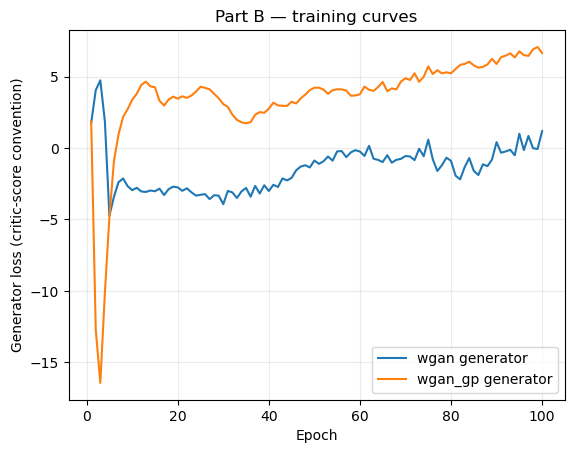

wgan — 100 samples


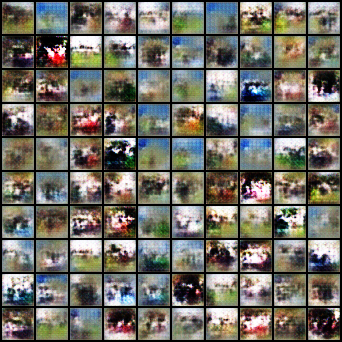

wgan_gp — 100 samples


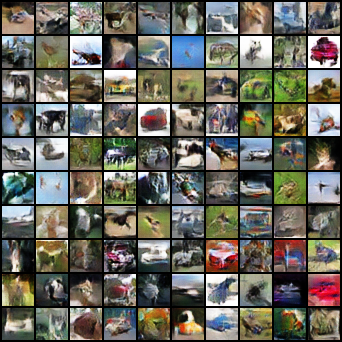

In [4]:
import json

for name in ("wgan", "wgan_gp"):
    with (OUTPUT_DIR / "curves" / f"{name}.json").open() as f:
        curve = json.load(f)
    plt.plot(curve["epoch"], curve["generator_loss"], label=f"{name} generator")
plt.xlabel("Epoch")
plt.ylabel("Generator loss (critic-score convention)")
plt.title("Part B — training curves")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

for name in ("wgan", "wgan_gp"):
    print(name, "— 100 samples")
    display(Image(filename=str(OUTPUT_DIR / "samples" / f"{name}_100.png")))
